<a href="https://colab.research.google.com/github/salioudunn11/Fitness_Prediction/blob/main/CST_3502_Results.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### UPDATED INFORMATION REGARDING PROJECT

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_recall_fscore_support, classification_report,
                             roc_curve, auc, precision_recall_curve, average_precision_score,
                             silhouette_score, adjusted_rand_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
RANDOM_STATE = 42

df = pd.read_csv("https://raw.githubusercontent.com/salioudunn11/Fitness_Prediction/main/gym_members_exercise_tracking.csv")
df = df.rename(columns={
    "Weight (kg)": "Weight", "Height (m)": "Height",
    "Session_Duration (hours)": "Duration",
    "Water_Intake (liters)": "Water_Intake",
    "Workout_Frequency (days/week)": "Frequency",
})
print(df.shape)

(973, 15)


### 1. Which attributes affect Calories_Burned the most?

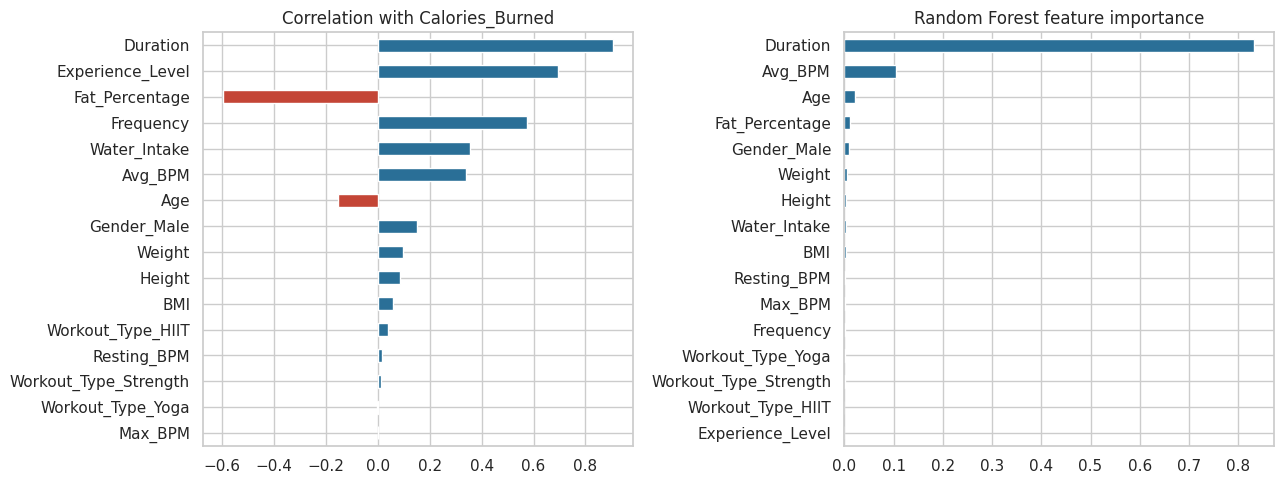

Selected features: ['Duration', 'Avg_BPM', 'Age', 'Fat_Percentage', 'Gender_Male', 'Weight']


In [ ]:
d = pd.get_dummies(df, columns=["Gender", "Workout_Type"], dtype=int, drop_first=True)
X_all = d.drop(columns="Calories_Burned")
y_cont = d["Calories_Burned"]

corr = d.corr()["Calories_Burned"].drop("Calories_Burned").sort_values(key=abs, ascending=False)
rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE).fit(X_all, y_cont)
importance = pd.Series(rf.feature_importances_, X_all.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
corr.plot.barh(ax=axes[0], color=["#2a6f97" if v > 0 else "#c44536" for v in corr]); axes[0].invert_yaxis()
axes[0].set_title("Correlation with Calories_Burned")
importance.plot.barh(ax=axes[1], color="#2a6f97"); axes[1].invert_yaxis()
axes[1].set_title("Random Forest feature importance")
plt.tight_layout(); plt.savefig("fig_feature_importance.png", dpi=150); plt.show()

FEATURES = importance.head(6).index.tolist()
print("Selected features:", FEATURES)

### 2. Target class: bin Calories_Burned into three equal-sized groups (tertiles)

In [ ]:
LABELS = ["Low", "Medium", "High"]
df["Calorie_Class"], bins = pd.qcut(df["Calories_Burned"], q=3, labels=LABELS, retbins=True)
print("Bin edges (kcal):", np.round(bins, 0))
print(df["Calorie_Class"].value_counts())

X = d[FEATURES]
y = df["Calorie_Class"].cat.codes          # 0 = Low, 1 = Medium, 2 = High

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(X_train)      # fit on train only (no leakage)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

Bin edges (kcal): [ 303.  784. 1006. 1783.]
Calorie_Class
Medium    325
Low       324
High      324
Name: count, dtype: int64


### 3. KNN: test different values of k

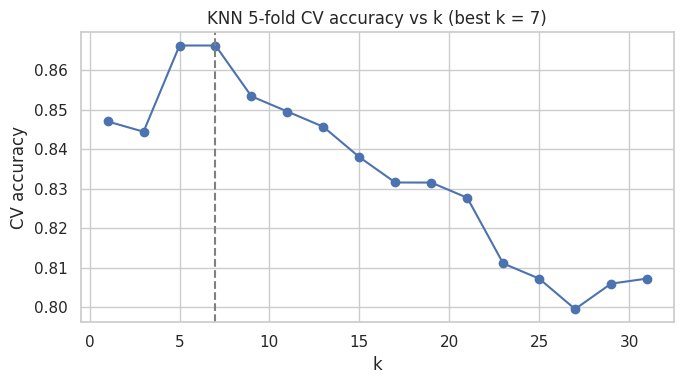

In [ ]:
k_values = range(1, 32, 2)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
k_scores = [cross_val_score(KNeighborsClassifier(k), X_train_s, y_train, cv=cv).mean() for k in k_values]
best_k = list(k_values)[int(np.argmax(k_scores))]

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), k_scores, marker="o")
plt.axvline(best_k, ls="--", c="gray")
plt.title(f"KNN 5-fold CV accuracy vs k (best k = {best_k})"); plt.xlabel("k"); plt.ylabel("CV accuracy")
plt.tight_layout(); plt.savefig("fig_knn_k.png", dpi=150); plt.show()


### 4. Train the models

In [ ]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    f"KNN (k={best_k})": KNeighborsClassifier(best_k),
    "Naive Bayes": GaussianNB(),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=2000, random_state=RANDOM_STATE),
}
results, probas, preds = [], {}, {}
for name, m in models.items():
    m.fit(X_train_s, y_train)
    preds[name] = m.predict(X_test_s)
    probas[name] = m.predict_proba(X_test_s)
    p, r, f, _ = precision_recall_fscore_support(y_test, preds[name], average="macro")
    results.append({"Model": name, "Accuracy": accuracy_score(y_test, preds[name]),
                    "Precision": p, "Recall": r, "F1": f})

results_df = pd.DataFrame(results).set_index("Model").round(3)
print(results_df)


                Accuracy  Precision  Recall     F1
Model                                             
Decision Tree      0.805      0.805   0.805  0.805
KNN (k=7)          0.856      0.858   0.856  0.857
Naive Bayes        0.738      0.771   0.738  0.742
Neural Network     0.913      0.916   0.913  0.913


### 5. Confusion matrices


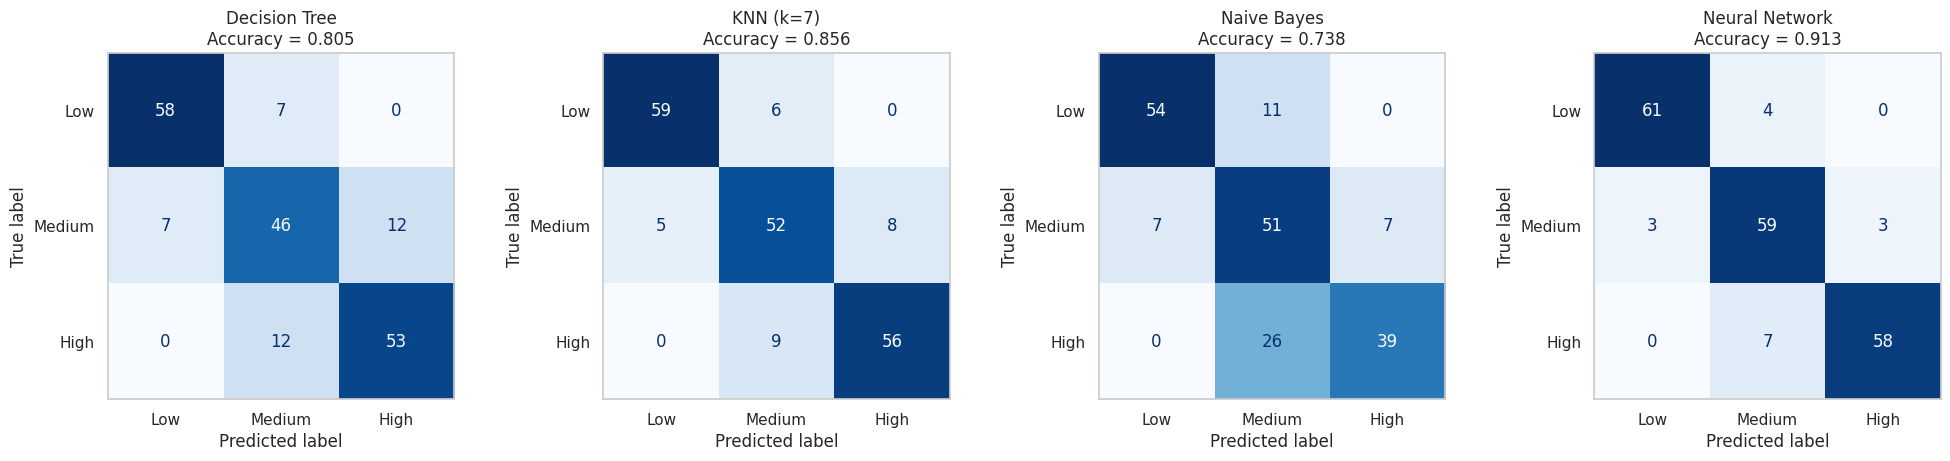


=== Decision Tree ===
              precision    recall  f1-score   support

         Low      0.892     0.892     0.892        65
      Medium      0.708     0.708     0.708        65
        High      0.815     0.815     0.815        65

    accuracy                          0.805       195
   macro avg      0.805     0.805     0.805       195
weighted avg      0.805     0.805     0.805       195


=== KNN (k=7) ===
              precision    recall  f1-score   support

         Low      0.922     0.908     0.915        65
      Medium      0.776     0.800     0.788        65
        High      0.875     0.862     0.868        65

    accuracy                          0.856       195
   macro avg      0.858     0.856     0.857       195
weighted avg      0.858     0.856     0.857       195


=== Naive Bayes ===
              precision    recall  f1-score   support

         Low      0.885     0.831     0.857        65
      Medium      0.580     0.785     0.667        65
        High

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.grid(False)
    ax.set_title(f"{name}\nAccuracy = {results_df.loc[name, 'Accuracy']:.3f}")
plt.tight_layout(); plt.savefig("fig_confusion_matrices.png", dpi=150); plt.show()

for name in models:
    print(f"\n=== {name} ===")
    print(classification_report(y_test, preds[name], target_names=LABELS, digits=3))


### 6. Metrics bar chart

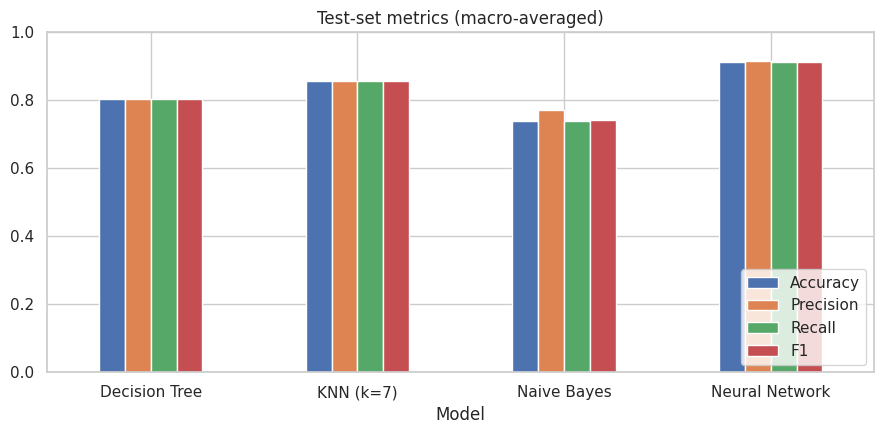

In [ ]:
results_df.plot.bar(figsize=(9, 4.5), ylim=(0, 1), rot=0)
plt.title("Test-set metrics (macro-averaged)"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("fig_metrics.png", dpi=150); plt.show()

### 7. ROC and Precision/Recall curves (one-vs-rest, macro average)

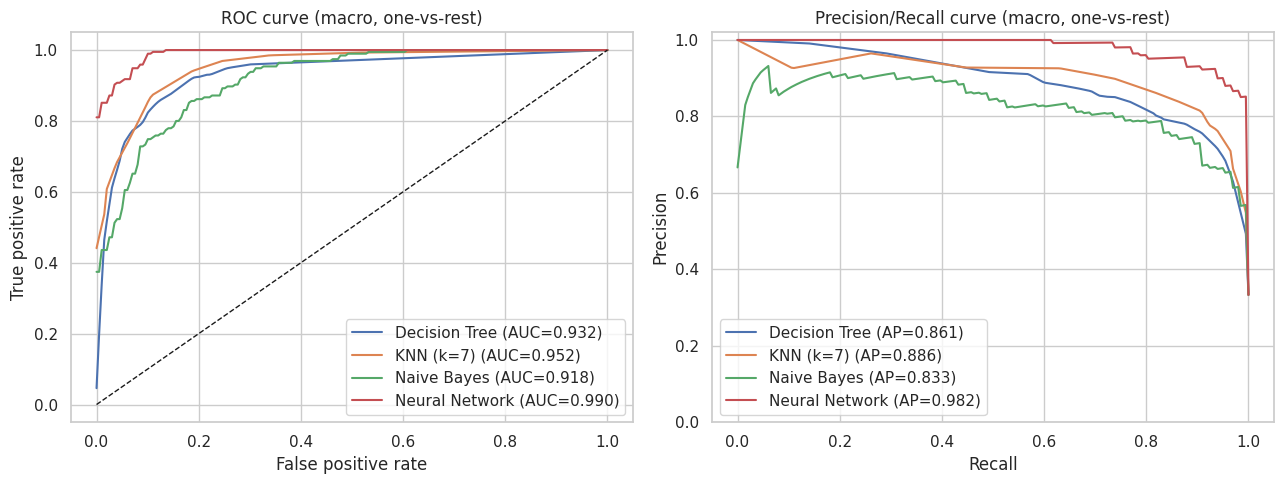

In [ ]:
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for name in models:
    P = probas[name]
    fpr_grid = np.linspace(0, 1, 200); tpr_mean = np.zeros_like(fpr_grid)
    for c in range(3):
        fpr, tpr, _ = roc_curve(y_test_bin[:, c], P[:, c])
        tpr_mean += np.interp(fpr_grid, fpr, tpr) / 3
    ax1.plot(fpr_grid, tpr_mean, label=f"{name} (AUC={auc(fpr_grid, tpr_mean):.3f})")

    rec_grid = np.linspace(0, 1, 200); prec_mean = np.zeros_like(rec_grid)
    for c in range(3):
        prec, rec, _ = precision_recall_curve(y_test_bin[:, c], P[:, c])
        prec_mean += np.interp(rec_grid, rec[::-1], prec[::-1]) / 3
    ap = average_precision_score(y_test_bin, P, average="macro")
    ax2.plot(rec_grid, prec_mean, label=f"{name} (AP={ap:.3f})")

ax1.plot([0, 1], [0, 1], "k--", lw=1); ax1.set(title="ROC curve (macro, one-vs-rest)",
                                              xlabel="False positive rate", ylabel="True positive rate")
ax2.set(title="Precision/Recall curve (macro, one-vs-rest)", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
ax1.legend(loc="lower right"); ax2.legend(loc="lower left")
plt.tight_layout(); plt.savefig("fig_roc_pr.png", dpi=150); plt.show()


### 8. Decision tree: top of the tree (the rules it learned)

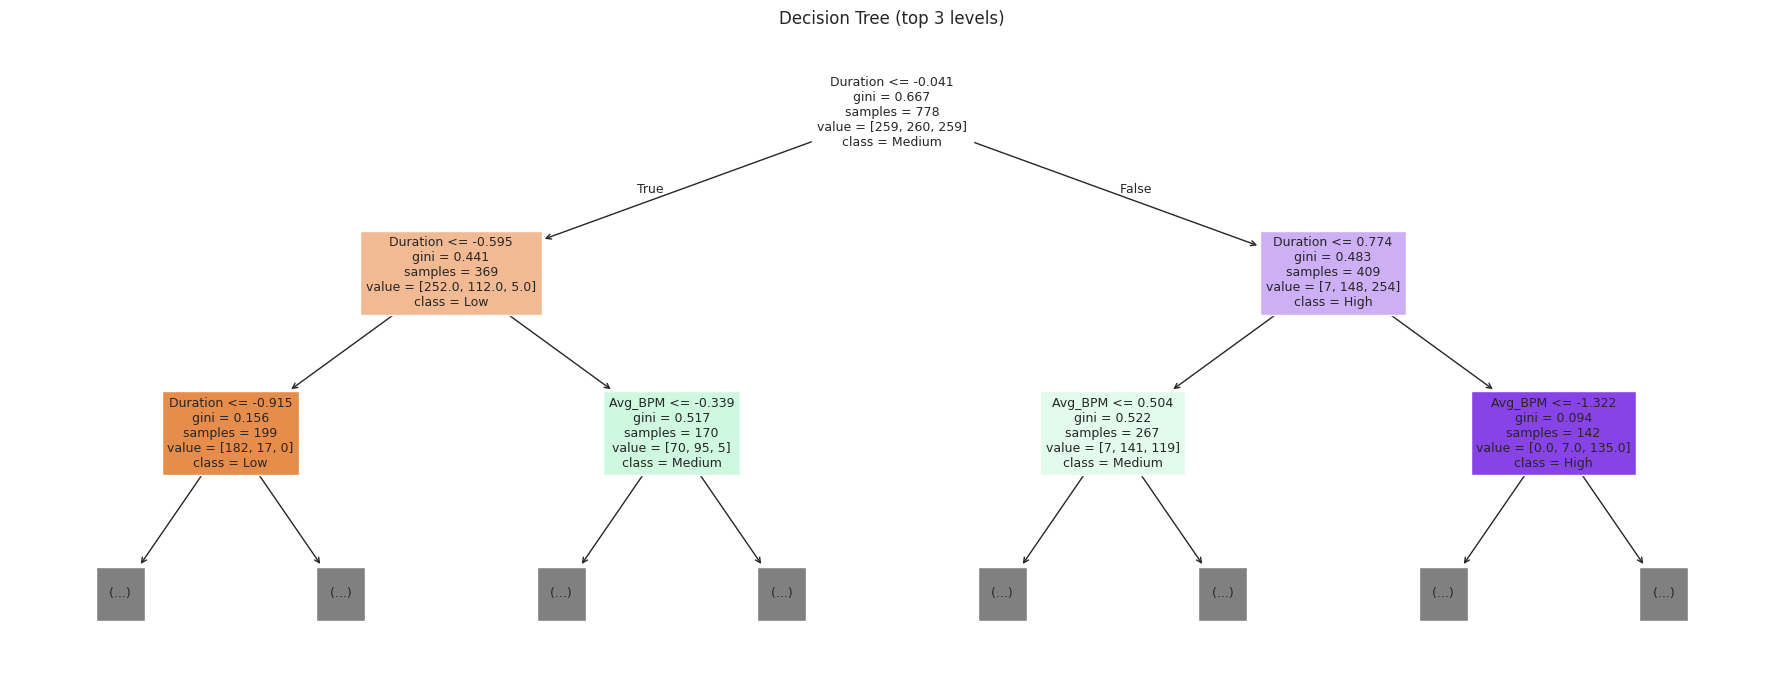

Silhouette score: 0.268
Adjusted Rand Index vs calorie class: 0.14
Calorie_Class  Low  Medium  High
Cluster                         
0                0      18   177
1              149     154   103
2              175     153    44
         Duration  Avg_BPM    Age  Calories_Burned
Cluster                                           
0            1.75   143.24  38.47          1261.14
1            1.13   143.67  39.14           847.17
2            1.14   144.14  38.30           782.54


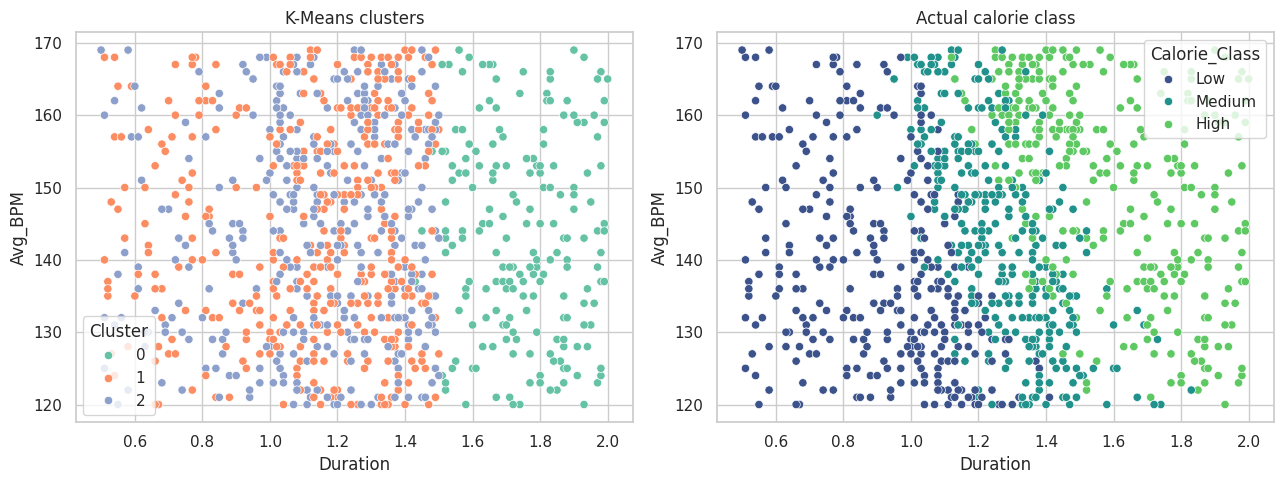

In [ ]:
plt.figure(figsize=(18, 7))
plot_tree(models["Decision Tree"], feature_names=FEATURES, class_names=LABELS,
          filled=True, max_depth=2, fontsize=9)
plt.title("Decision Tree (top 3 levels)")
plt.tight_layout(); plt.savefig("fig_decision_tree.png", dpi=150); plt.show()

# %% 9. Clustering on features only (K-Means, k = 3, labels NOT used to fit)
X_all_s = StandardScaler().fit_transform(X)
km = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_all_s)
df["Cluster"] = km.labels_
print("Silhouette score:", round(silhouette_score(X_all_s, km.labels_), 3))
print("Adjusted Rand Index vs calorie class:", round(adjusted_rand_score(y, km.labels_), 3))
print(pd.crosstab(df["Cluster"], df["Calorie_Class"]))
print(df.groupby("Cluster")[["Duration", "Avg_BPM", "Age", "Calories_Burned"]].mean().round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="Duration", y="Avg_BPM", hue="Cluster", palette="Set2", ax=ax[0]).set_title("K-Means clusters")
sns.scatterplot(data=df, x="Duration", y="Avg_BPM", hue="Calorie_Class", palette="viridis", ax=ax[1]).set_title("Actual calorie class")
plt.tight_layout(); plt.savefig("fig_clusters.png", dpi=150); plt.show()
